# RMSD and RMSF: Baseline vs PTR253 (KSHV SOX, 3POV)

Comparison of the unphosphorylated (baseline) and phosphotyrosine 253 (PTR) systems, 3 replicas each.

- Trajectories are aligned on a **stable core**: the 30% lowest-RMSF residues of baseline replica 1, used for both systems
- Residue numbers follow the topology (+2 relative to the crystal structure)
- Catalytic residues: E186, D223, E246, K248 (+ Mg²⁺); PTR region: residues 284–289

Trajectories and topologies are not included in the repository.

In [ ]:
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn
warnings.filterwarnings("ignore")

## RMSD per region

Mean ± SD over 3 replicas for the full protein, the catalytic site (with Mg²⁺) and the PTR region.

Finding stable core from baseline...


Stable core: 147 residues (threshold: 0.72 Å)
Computing Baseline...
Computing PTR...
Full protein:
  Baseline: 2.648 ± 0.200 Å
  PTR:      2.671 ± 0.174 Å
Catalytic (MG, E186, D223, E246, K248):
  Baseline: 1.251 ± 0.502 Å
  PTR:      0.879 ± 0.135 Å
PTR253 region (284-289):
  Baseline: 0.323 ± 0.007 Å
  PTR:      0.748 ± 0.037 Å


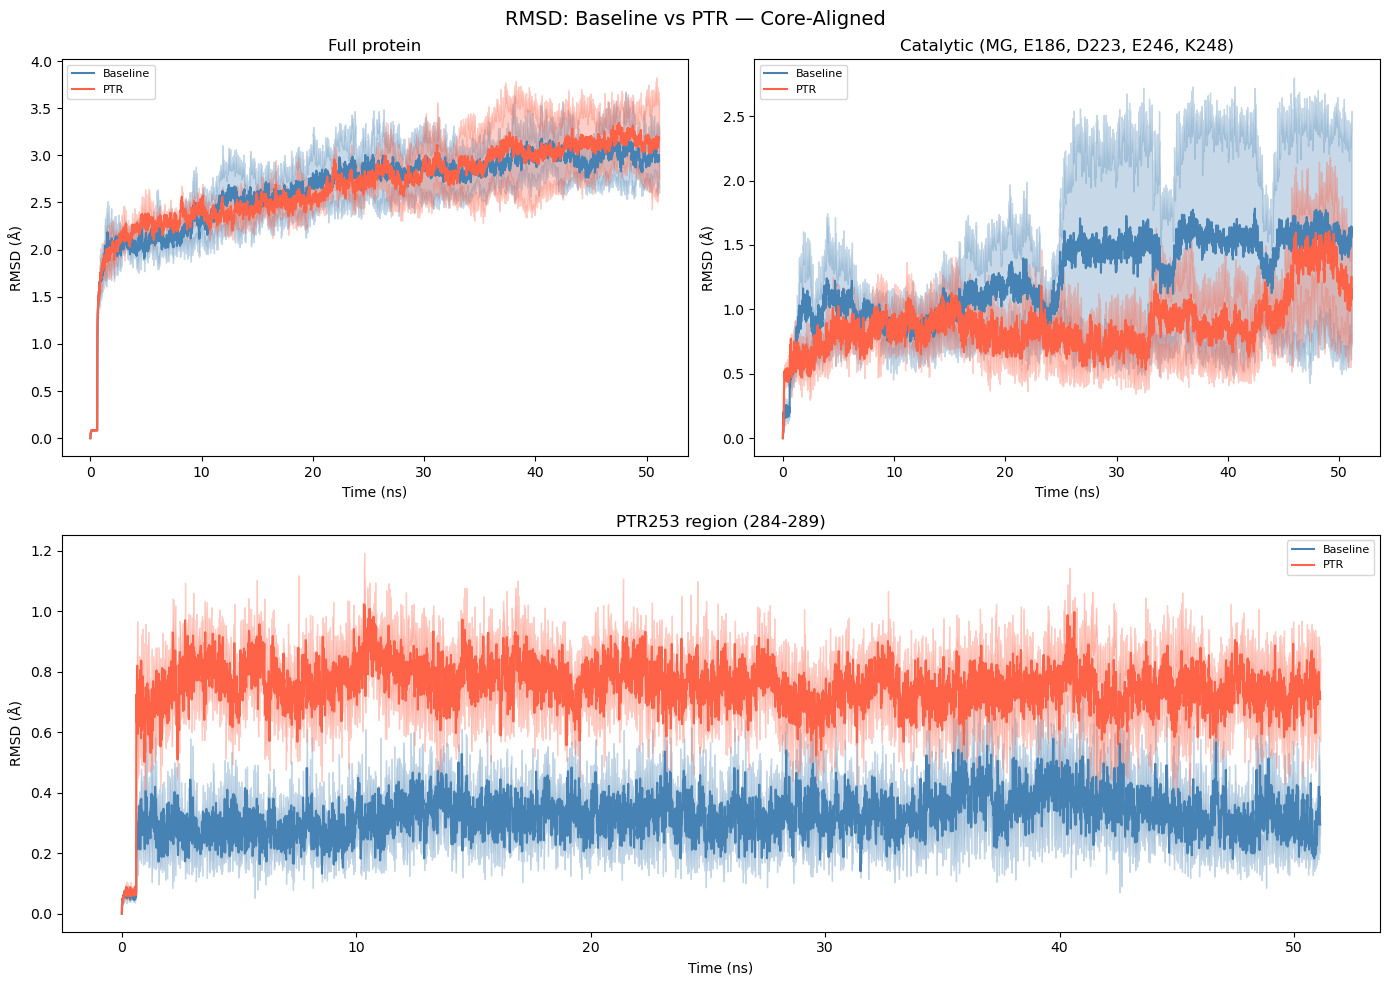

In [ ]:
import MDAnalysis as mda
from MDAnalysis.analysis import align
from MDAnalysis.analysis.rms import RMSF, RMSD
import numpy as np
import matplotlib.pyplot as plt

ptr_top = "/home/mk-avid-workstation/MD Sim/3POV/ptr.prmtop"
base_top = "/home/mk-avid-workstation/MD Sim/3POV/baseline.prmtop"
ptr_trajs = [f"/home/mk-avid-workstation/MD Sim/PTR_3POV_{i}/trajectory.dcd" for i in range(1,4)]
base_trajs = [f"/home/mk-avid-workstation/MD Sim/Baseline_3POV_{i}/trajectory.dcd" for i in range(1,4)]

NS_PER_FRAME = 0.01  # 5000 frames = 50 ns -> 0.01 ns (10 ps) per frame

ca_sel = "(protein or resname PTR) and name CA"
bb_sel = "(protein or resname PTR) and backbone"


def find_stable_core(top, traj, percentile=30):
    u = mda.Universe(top, traj)
    ref = mda.Universe(top, traj)
    ca = u.select_atoms(ca_sel)
    align.AlignTraj(u, ref, select=bb_sel, in_memory=True).run()
    rmsf_vals = RMSF(ca).run().results.rmsf
    threshold = np.percentile(rmsf_vals, percentile)
    stable_resids = ca.resids[rmsf_vals <= threshold]
    core = " or ".join([f"resid {r}" for r in stable_resids])
    print(f"Stable core: {len(stable_resids)} residues (threshold: {threshold:.2f} Å)")
    return f"(protein or resname PTR) and backbone and ({core})"


regions = {
    "Full protein":            ca_sel,
    "Catalytic (MG, E186, D223, E246, K248)": f"resname MG or ({ca_sel} and resid 186 223 246 248)",
    "PTR253 region (284-289)": f"{ca_sel} and resid 284:289",
}


def get_all_rmsd(top, traj, core_sel):
    u = mda.Universe(top, traj)
    ref = mda.Universe(top, traj)
    align.AlignTraj(u, ref, select=core_sel, in_memory=True).run()
    results = {}
    for name, sel in regions.items():
        rmsd_calc = RMSD(u, ref, select=sel, ref_frame=0)
        rmsd_calc.run()
        results[name] = rmsd_calc.results.rmsd[:, 2]
    return results


print("Finding stable core from baseline...")
shared_core = find_stable_core(base_top, base_trajs[0])

print("Computing Baseline...")
base_results = [get_all_rmsd(base_top, t, shared_core) for t in base_trajs]
print("Computing PTR...")
ptr_results = [get_all_rmsd(ptr_top, t, shared_core) for t in ptr_trajs]

fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(2, 2)
plot_axes = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, :]),   # bottom plot spans both columns, centered
]

for idx, name in enumerate(regions):
    ptr_rmsds = [r[name] for r in ptr_results]
    base_rmsds = [r[name] for r in base_results]

    min_p = min(len(r) for r in ptr_rmsds)
    min_b = min(len(r) for r in base_rmsds)
    ptr_arr = np.array([r[:min_p] for r in ptr_rmsds])
    base_arr = np.array([r[:min_b] for r in base_rmsds])

    time_b = np.arange(min_b) * NS_PER_FRAME
    time_p = np.arange(min_p) * NS_PER_FRAME

    ax = plot_axes[idx]
    ax.plot(time_b, base_arr.mean(0), label="Baseline", color="steelblue")
    ax.fill_between(time_b, base_arr.mean(0)-base_arr.std(0),
                    base_arr.mean(0)+base_arr.std(0), alpha=0.3, color="steelblue")
    ax.plot(time_p, ptr_arr.mean(0), label="PTR", color="tomato")
    ax.fill_between(time_p, ptr_arr.mean(0)-ptr_arr.std(0),
                    ptr_arr.mean(0)+ptr_arr.std(0), alpha=0.3, color="tomato")
    ax.set_xlabel("Time (ns)")
    ax.set_xlabel("Time (ns)")
    ax.set_ylabel("RMSD (Å)")
    ax.set_title(name)
    ax.legend(fontsize=8)

    print(f"{name}:")
    print(f"  Baseline: {np.mean([r.mean() for r in base_rmsds]):.3f} ± {np.std([r.mean() for r in base_rmsds]):.3f} Å")
    print(f"  PTR:      {np.mean([r.mean() for r in ptr_rmsds]):.3f} ± {np.std([r.mean() for r in ptr_rmsds]):.3f} Å")

plt.suptitle("RMSD: Baseline vs PTR — Core-Aligned", fontsize=14)
plt.tight_layout()
plt.savefig("rmsd_all_regions.png", dpi=300)
plt.show()

## Per-residue RMSF

Cα RMSF after two-pass alignment (core, then average structure). Bottom panel: ΔRMSF (PTR − Baseline).

Stable core: 147 residues (threshold: 0.72 Å)
Computing Baseline RMSF...
Computing PTR RMSF...


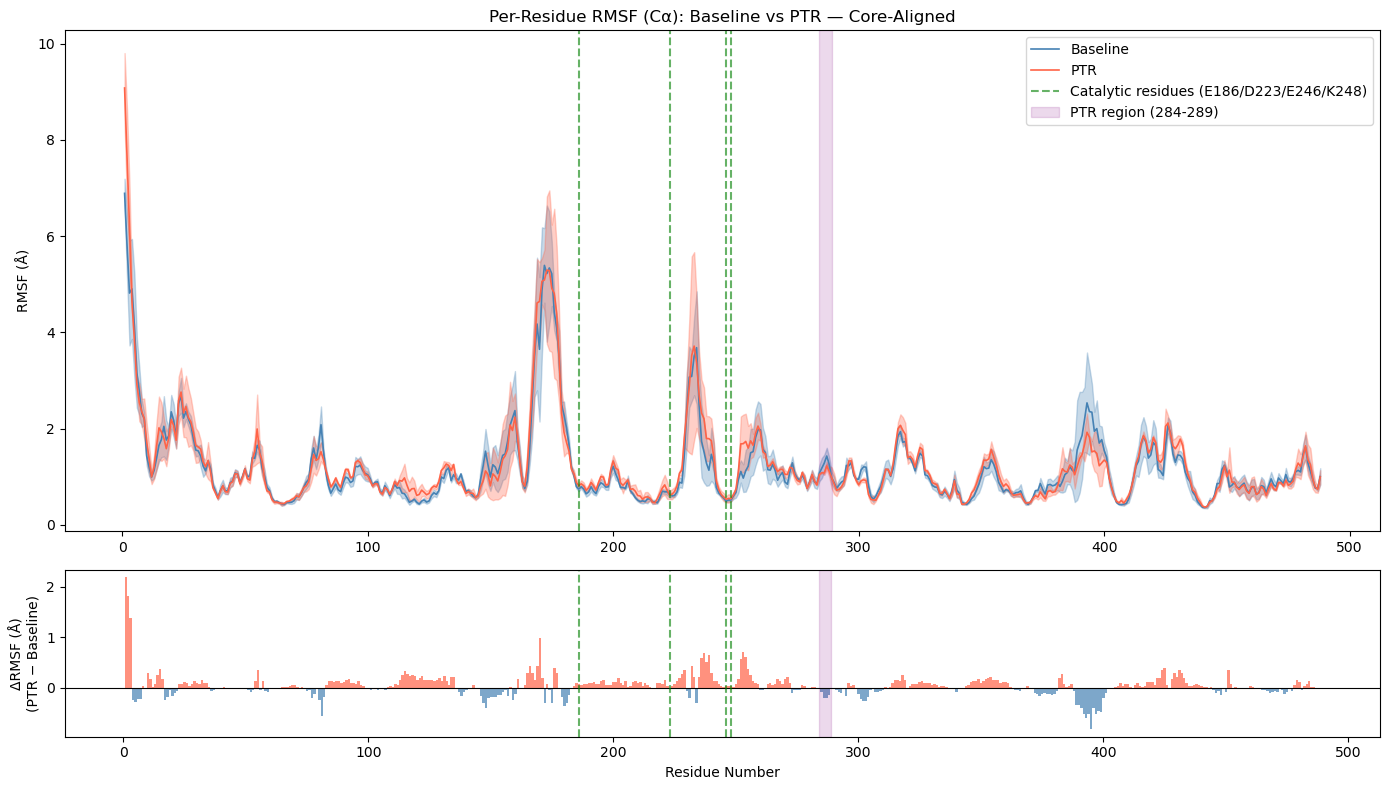


Baseline RMSF median: 0.94 Å
PTR RMSF median:      0.97 Å


In [ ]:
import MDAnalysis as mda
from MDAnalysis.analysis import align
from MDAnalysis.analysis.rms import RMSF
import numpy as np
import matplotlib.pyplot as plt

ptr_top = "/home/mk-avid-workstation/MD Sim/3POV/ptr.prmtop"
base_top = "/home/mk-avid-workstation/MD Sim/3POV/baseline.prmtop"
ptr_trajs = [f"/home/mk-avid-workstation/MD Sim/PTR_3POV_{i}/trajectory.dcd" for i in range(1,4)]
base_trajs = [f"/home/mk-avid-workstation/MD Sim/Baseline_3POV_{i}/trajectory.dcd" for i in range(1,4)]

ca_sel = "(protein or resname PTR) and name CA"
bb_sel = "(protein or resname PTR) and backbone"

# Catalytic residues (matches RMSD script: MG handled separately, these are the protein residues)
catalytic_resids = [186, 223, 246, 248]
ptr_region = (284, 289)


def find_stable_core(top, traj, percentile=30):
    u = mda.Universe(top, traj)
    ref = mda.Universe(top, traj)
    ca = u.select_atoms(ca_sel)
    align.AlignTraj(u, ref, select=bb_sel, in_memory=True).run()
    rmsf_vals = RMSF(ca).run().results.rmsf
    threshold = np.percentile(rmsf_vals, percentile)
    stable_resids = ca.resids[rmsf_vals <= threshold]
    core = " or ".join([f"resid {r}" for r in stable_resids])
    print(f"Stable core: {len(stable_resids)} residues (threshold: {threshold:.2f} Å)")
    return f"(protein or resname PTR) and backbone and ({core})"


def get_rmsf(top, traj, core_sel):
    u = mda.Universe(top, traj)
    ref = mda.Universe(top, traj)
    ca = u.select_atoms(ca_sel)
    align.AlignTraj(u, ref, select=core_sel, in_memory=True).run()
    avg = align.AverageStructure(u, u, select=core_sel).run()
    align.AlignTraj(u, avg.results.universe, select=core_sel, in_memory=True).run()
    return ca.resids, RMSF(ca).run().results.rmsf


# Stable core from BASELINE (reference state)
shared_core = find_stable_core(base_top, base_trajs[0])

# Compute — same core for both
print("Computing Baseline RMSF...")
base_data = [get_rmsf(base_top, t, shared_core) for t in base_trajs]
print("Computing PTR RMSF...")
ptr_data = [get_rmsf(ptr_top, t, shared_core) for t in ptr_trajs]

resids = ptr_data[0][0]
ptr_rmsf = np.array([d[1] for d in ptr_data])
base_rmsf = np.array([d[1] for d in base_data])

# Plot
fig, axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [3, 1]})

ax = axes[0]
ax.plot(resids, base_rmsf.mean(0), label="Baseline", color="steelblue", lw=1.2)
ax.fill_between(resids, base_rmsf.mean(0)-base_rmsf.std(0),
                base_rmsf.mean(0)+base_rmsf.std(0), alpha=0.3, color="steelblue")
ax.plot(resids, ptr_rmsf.mean(0), label="PTR", color="tomato", lw=1.2)
ax.fill_between(resids, ptr_rmsf.mean(0)-ptr_rmsf.std(0),
                ptr_rmsf.mean(0)+ptr_rmsf.std(0), alpha=0.3, color="tomato")
for i, r in enumerate(catalytic_resids):
    ax.axvline(r, color='green', ls='--', alpha=0.6,
               label='Catalytic residues (E186/D223/E246/K248)' if i == 0 else None)
ax.axvspan(*ptr_region, alpha=0.15, color='purple', label='PTR region (284-289)')
ax.set_ylabel("RMSF (Å)")
ax.set_title("Per-Residue RMSF (Cα): Baseline vs PTR — Core-Aligned")
ax.legend()

diff = ptr_rmsf.mean(0) - base_rmsf.mean(0)
axes[1].bar(resids, diff, width=1, color=np.where(diff > 0, 'tomato', 'steelblue'), alpha=0.7)
axes[1].axhline(0, color='black', lw=0.8)
for r in catalytic_resids:
    axes[1].axvline(r, color='green', ls='--', alpha=0.6)
axes[1].axvspan(*ptr_region, alpha=0.15, color='purple')
axes[1].set_xlabel("Residue Number")
axes[1].set_ylabel("ΔRMSF (Å)\n(PTR − Baseline)")

plt.tight_layout()
plt.savefig("rmsf_final.png", dpi=300)
plt.show()

# Stats
print(f"\nBaseline RMSF median: {np.median(base_rmsf.mean(0)):.2f} Å")
print(f"PTR RMSF median:      {np.median(ptr_rmsf.mean(0)):.2f} Å")